# 03 — Fine-tuning de DistilBERT et comparaison
**Objectif :** adapter DistilBERT aux 77 intentions bancaires et comparer ses performances à celles du modèle TF-IDF.

**Prérequis :** notebooks 01 et 02 exécutés. Une connexion Internet est nécessaire au premier téléchargement de DistilBERT. Un GPU est conseillé ; sur CPU, les 10 époques peuvent prendre beaucoup de temps.

Les paramètres d'origine sont conservés : longueur maximale 128, taux d'apprentissage 2e-5, 10 époques, lots de 8 et accumulation sur 2 étapes. Le meilleur checkpoint est sélectionné selon le macro-F1 de validation.

In [1]:
from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"
for directory in (DATA_DIR, RESULTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

from time import perf_counter
import numpy as np
import torch
import joblib
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    TrainingArguments, Trainer, set_seed,
)

W1015 13:19:07.177000 25412 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


## 1. Charger les données et vérifier le matériel

In [2]:
required = [DATA_DIR / name for name in ("train.csv", "validation.csv", "categories.json")]
for path in required:
    if not path.exists():
        raise FileNotFoundError(f"Fichier absent : {path}. Exécuter d'abord le notebook 01.")
train_df = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False)
val_df = pd.read_csv(DATA_DIR / "validation.csv", keep_default_na=False)
categories = pd.Index(json.loads((DATA_DIR / "categories.json").read_text(encoding="utf-8")))
print(f"Train : {len(train_df)} | Validation : {len(val_df)} | Catégories : {len(categories)}")

Train : 7993 | Validation : 1999 | Catégories : 77


In [3]:
baseline_path = MODELS_DIR / "baseline.joblib"
if not baseline_path.exists():
    raise FileNotFoundError("Exécuter d'abord le notebook 02 pour sauvegarder la baseline.")
baseline = joblib.load(baseline_path)

In [4]:
print("CUDA disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

CUDA disponible : True
GPU : NVIDIA GeForce RTX 4060 Laptop GPU


In [5]:
train_dataset = Dataset.from_pandas(train_df[["text", "labels"]], preserve_index=False)
val_dataset = Dataset.from_pandas(val_df[["text", "labels"]], preserve_index=False)

## 2. Tokeniser les messages

In [6]:
MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [7]:
def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

train_tokens = train_dataset.map(tokenize, batched=True, remove_columns=["text"])
val_tokens = val_dataset.map(tokenize, batched=True, remove_columns=["text"])

print("Colonnes :", train_tokens.column_names)

Map:   0%|          | 0/7993 [00:00<?, ? examples/s]

Map:   0%|          | 0/1999 [00:00<?, ? examples/s]

Colonnes : ['labels', 'input_ids', 'token_type_ids', 'attention_mask']


## 3. Préparer les lots
Le padding dynamique ajuste la longueur au message le plus long de chaque lot.

In [8]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

example_batch = data_collator([train_tokens[i] for i in range(2)])
print("Taille du lot :", example_batch["input_ids"].shape)
print("Labels :", example_batch["labels"])

Taille du lot : torch.Size([2, 19])
Labels : tensor([0, 1])


## 4. Charger le modèle et associer les catégories

In [9]:
label2id = {label: number for number, label in enumerate(categories)}
id2label = {number: label for number, label in enumerate(categories)}
set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    label2id=label2id,
    id2label=id2label,
)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Paramètres entraînables : {trainable:,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Paramètres entraînables : 67,012,685


## 5. Définir les mêmes métriques que pour la baseline

In [10]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro", zero_division=0
        ),
    }

## 6. Configurer l’entraînement

In [11]:
OUTPUT_DIR = MODELS_DIR / "distilbert_checkpoints"

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),
    learning_rate=2e-5,
    num_train_epochs=10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=50,
    report_to="none",
    seed=42,
)

In [12]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokens,
    eval_dataset=val_tokens,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

## 7. Lancer le fine-tuning

In [13]:
if torch.cuda.is_available():
    torch.cuda.synchronize()
start = perf_counter()

trainer.train()

if torch.cuda.is_available():
    torch.cuda.synchronize()
training_seconds = perf_counter() - start
print(f"Durée totale : {training_seconds / 60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,4.684419,2.097353,0.686343,0.617027
2,1.997990,0.924738,0.840920,0.809111
3,1.093235,0.556821,0.873437,0.862147
4,0.566120,0.397413,0.906453,0.906389
5,0.391374,0.353330,0.905453,0.906303
6,0.297535,0.332941,0.911456,0.912028
7,0.111749,0.339695,0.913957,0.914681
8,0.103528,0.331587,0.914957,0.915275
9,0.063000,0.338006,0.913457,0.914385
10,0.061201,0.338135,0.915458,0.916093


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Durée totale : 11.8 minutes


## 8. Comparer les deux modèles sur la validation
Les deux modèles utilisent exactement le même découpage. Les scores de validation servent au choix du modèle ; ils ne remplacent pas une évaluation finale sur le test.

In [14]:
baseline_predictions = baseline.predict(val_df["text"])
baseline_metrics = {
    "accuracy": accuracy_score(val_df["category"], baseline_predictions),
    "macro_f1": f1_score(
        val_df["category"], baseline_predictions, average="macro", zero_division=0
    ),
}

metrics = trainer.evaluate(eval_dataset=val_tokens)

comparison = pd.DataFrame([
    {
        "modele": "TF-IDF + régression logistique",
        "accuracy": baseline_metrics["accuracy"],
        "macro_f1": baseline_metrics["macro_f1"],
    },
    {
        "modele": "DistilBERT fine-tuné",
        "accuracy": metrics["eval_accuracy"],
        "macro_f1": metrics["eval_macro_f1"],
    },
])
print(comparison.round(4).to_string(index=False))

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.061201,0.338135,10,0.915458,0.916093


                        modele  accuracy  macro_f1
TF-IDF + régression logistique    0.8479    0.8408
          DistilBERT fine-tuné    0.9155    0.9161


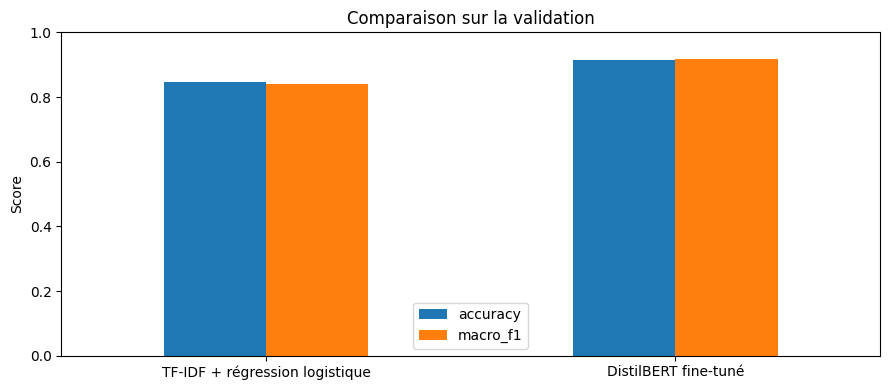

In [15]:
comparison.to_csv(RESULTS_DIR / "comparison_validation.csv", index=False)
import matplotlib.pyplot as plt
ax = comparison.set_index("modele")[["accuracy", "macro_f1"]].plot.bar(
    figsize=(9, 4), ylim=(0, 1), rot=0, title="Comparaison sur la validation"
)
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_validation.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Sauvegarder DistilBERT et analyser ses erreurs

In [16]:
FINAL_MODEL_DIR = MODELS_DIR / "distilbert_final"
trainer.save_model(str(FINAL_MODEL_DIR))
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))
(RESULTS_DIR / "distilbert_metrics.json").write_text(
    json.dumps({**metrics, "training_seconds": training_seconds}, indent=2), encoding="utf-8"
)
val_output = trainer.predict(val_tokens)
val_predictions = np.argmax(val_output.predictions, axis=-1)
bert_results = val_df[["text", "category"]].copy()
bert_results["prediction"] = categories.take(val_predictions)
bert_results.to_csv(RESULTS_DIR / "distilbert_validation_predictions.csv", index=False)
bert_results.loc[bert_results["category"] != bert_results["prediction"]].head(10)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,text,category,prediction
24,i disagree with a charge,card_payment_not_recognised,direct_debit_payment_not_recognised
25,Do I have to pick a creditcard brand?,visa_or_mastercard,supported_cards_and_currencies
26,Why is your exchange rate different on differe...,exchange_rate,wrong_exchange_rate_for_cash_withdrawal
41,What was the cause for my card to be declined?,declined_cash_withdrawal,declined_card_payment
51,Will I be charged to top off my account?,top_up_by_bank_transfer_charge,top_up_by_card_charge
78,How long does a transfer take?,pending_transfer,balance_not_updated_after_bank_transfer
80,I only have a card from the US is that okay?,supported_cards_and_currencies,country_support
85,My wallet is empty even though I topped it up ...,topping_up_by_card,pending_top_up
86,Why hasn't my transfer gone through,failed_transfer,balance_not_updated_after_bank_transfer
102,What apps can I use to top up my account?,top_up_by_cash_or_cheque,apple_pay_or_google_pay


## 10. Évaluation finale sur le test — facultative
Exécuter cette étape une fois les réglages fixés. Ne pas utiliser ces résultats pour modifier les paramètres : cela ferait perdre au test son rôle d'évaluation indépendante. Activer le drapeau ci-dessous pour évaluer les deux modèles, sans réentraînement.

In [19]:


test_df = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False)
test_df["labels"] = categories.get_indexer(test_df["category"])
assert (test_df["labels"] >= 0).all(), "Le test contient des catégories inconnues."
test_dataset = Dataset.from_pandas(test_df[["text", "labels"]], preserve_index=False)
test_tokens = test_dataset.map(tokenize, batched=True, remove_columns=["text"])
test_output = trainer.predict(test_tokens)
bert_test_predictions = categories.take(np.argmax(test_output.predictions, axis=-1))
baseline_test_predictions = baseline.predict(test_df["text"])
rows = []
for name, predictions in (
    ("TF-IDF + régression logistique", baseline_test_predictions),
    ("DistilBERT fine-tuné", bert_test_predictions),
):
    rows.append({
        "modele": name,
        "accuracy": accuracy_score(test_df["category"], predictions),
        "macro_f1": f1_score(test_df["category"], predictions, average="macro", zero_division=0),
    })
test_comparison = pd.DataFrame(rows)
test_comparison.to_csv(RESULTS_DIR / "comparison_test.csv", index=False)
print(test_comparison.round(4).to_string(index=False))

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

                        modele  accuracy  macro_f1
TF-IDF + régression logistique    0.8412    0.8389
          DistilBERT fine-tuné    0.9175    0.9178
